In [83]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [84]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

### Shifting Wannier functions

In [85]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=8)

In [86]:
plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\left(0, a_M\\right)$')

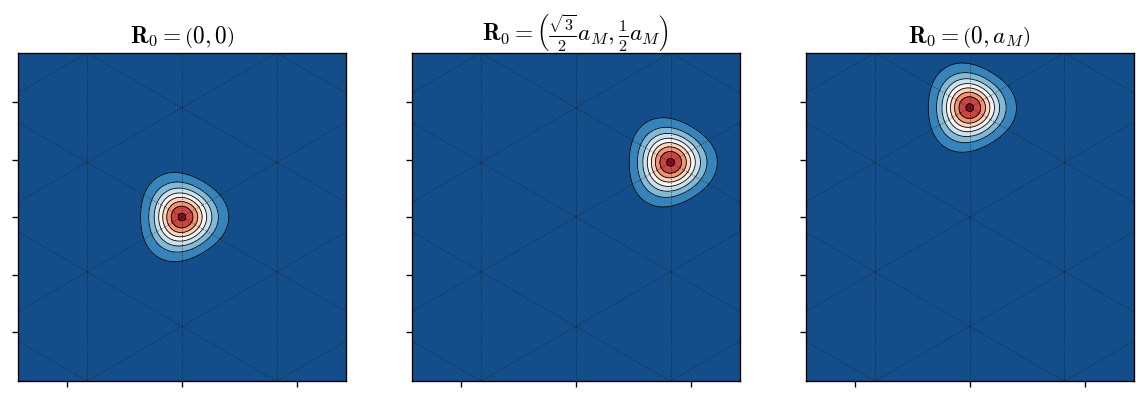

In [10]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3
##

fig, ax = plt.subplots(1, 3, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)
sys.plot_triangular_lattice(ax[0], extent)
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

im = sys.plot_wannier_function(ax[1], X, Y, k_points, R0=np.array([np.sqrt(3) * sys.aM / 2, sys.aM / 2]))
sys.plot_triangular_lattice(ax[1], extent)
ax[1].set_title(r"$\mathbf{R}_0 = \left(\frac{\sqrt{3}}{2}a_M, \frac{1}{2}a_M\right)$")

im = sys.plot_wannier_function(ax[2], X, Y, k_points, R0=np.array([0.0, sys.aM]))
sys.plot_triangular_lattice(ax[2], extent)
ax[2].set_title(r"$\mathbf{R}_0 = \left(0, a_M\right)$")

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\left(0, a_M\\right)$')

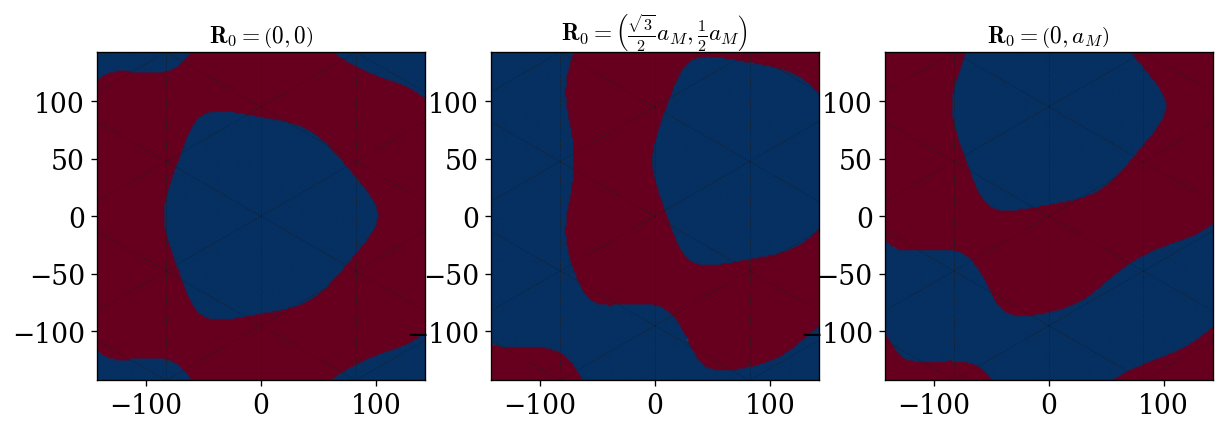

In [11]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3
##

fig, ax = plt.subplots(1, 3, figsize=(12, 8))
wannier = sys.wannier_wavefunction(X, Y, k_points)
im = sys.plot_wavefunction_phase(ax[0], wannier, extent)
sys.plot_triangular_lattice(ax[0], extent)
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.array([np.sqrt(3) * sys.aM / 2, sys.aM / 2]))
im = sys.plot_wavefunction_phase(ax[1], wannier, extent)
sys.plot_triangular_lattice(ax[1], extent)
ax[1].set_title(r"$\mathbf{R}_0 = \left(\frac{\sqrt{3}}{2}a_M, \frac{1}{2}a_M\right)$")

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.array([0.0, sys.aM]))
im = sys.plot_wavefunction_phase(ax[2], wannier, extent)
sys.plot_triangular_lattice(ax[2], extent)
ax[2].set_title(r"$\mathbf{R}_0 = \left(0, a_M\right)$")

### Set $V$ and $\psi$

In [12]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=8)

## On-site interaction

In [24]:
thetas = np.linspace(0.5, 3.0, 20)
U0 = []
U1 = []
U2 = []

scale = 4.0

Nx = 80
Ny = 80
D_gate = 1e6

for th in tqdm(thetas):
    sys.theta_deg = th
    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    U0.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate) / 1000)
    U1.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=1, D=D_gate) / 1000)
    U2.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=2, D=D_gate) / 1000)

  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [03:45<00:00, 11.28s/it]


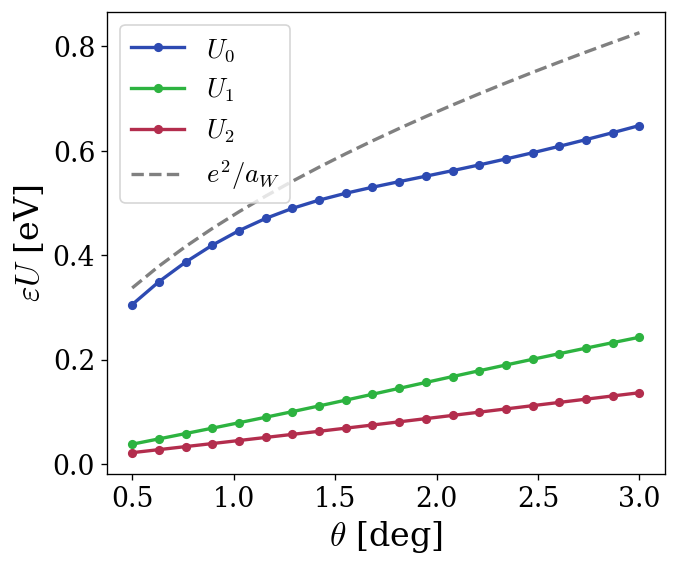

In [25]:
fig, ax = plt.subplots()

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]


ax.plot(thetas, U0, marker="o", label=r"$U_{0}$", markersize=4.5, color=cols[0])
ax.plot(thetas, U1, marker="o", label=r"$U_{1}$", markersize=4.5, color=cols[1])
ax.plot(thetas, U2, marker="o", label=r"$U_{2}$", markersize=4.5, color=cols[2])


aMs = sys.a0 / (2 * np.sin(np.radians(thetas) / 2))
ax.plot(thetas, utils.CHARGE_SQUARED / (utils.spread_harmonic_approx(aMs, sys.V, sys.psi) * 1000),
       color="gray", linestyle="--", label=r"$e^2/a_W$", linewidth=2)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon U$ [eV]", fontsize=20)
ax.legend(fontsize=16)
plt.savefig("plots/coulomb_interactions_bare.pdf", dpi=300, bbox_inches="tight")

### Exchange interaction

In [8]:
thetas = np.linspace(0.5, 3.0, 30)
E = []
t1 = []
lg = []

resk = 15
D_gate = 1e6

sys.n_shells = 8

for th in tqdm(thetas):
    sys.theta_deg = th
    k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    E.append(sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate))
    t1.append(sys.hopping_integral(X, Y, k_points, order=1))

    integral = sys.integrate_trace(Nx=resk, Ny=resk)
    l_trace = np.sqrt(integral) / sys.aM
    lg.append(l_trace)

  0%|          | 0/30 [00:00<?, ?it/s]

100%|██████████| 30/30 [02:56<00:00,  5.88s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


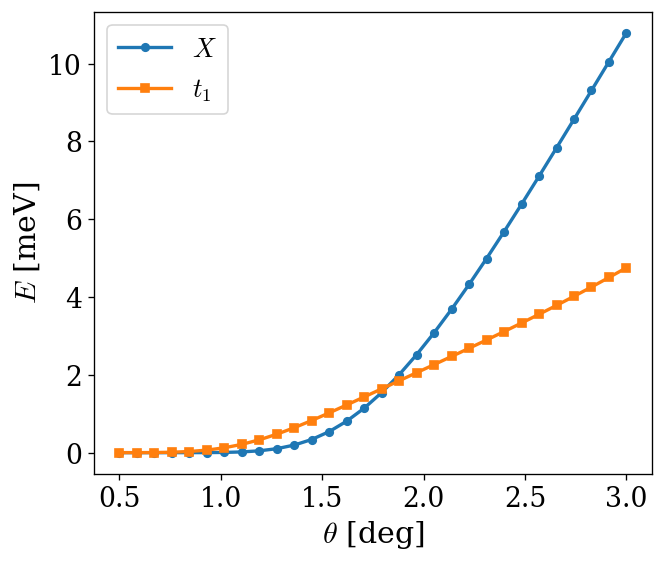

In [9]:
fig, ax = plt.subplots()
ax.plot(thetas, np.array(E), marker="o", label=r"$X$", markersize=4.5)
ax.plot(thetas, t1, marker="s", label=r"$t_1$", markersize=4.5)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=18)
ax.set_ylabel(r"$E$ [meV]", fontsize=18)
ax.legend(fontsize=16)

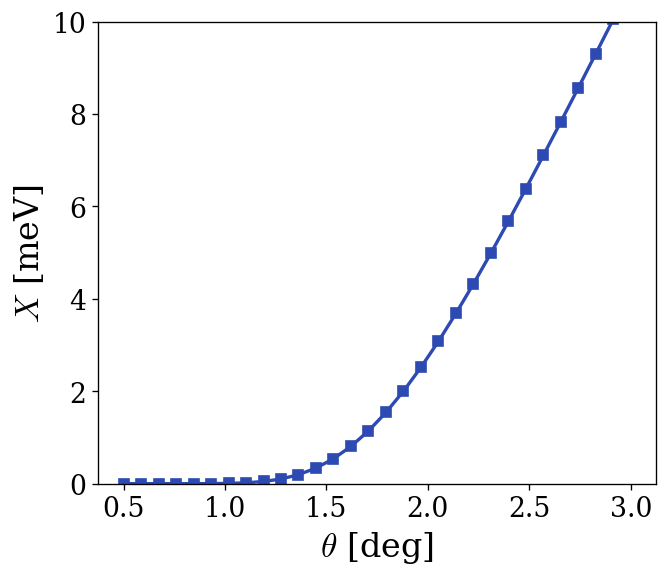

In [10]:
tt = np.linspace(0.001, 1.5, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))

fig, ax = plt.subplots()

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]
color1 = cols[0]
ax.plot(thetas, np.array(E), marker="s", label=r"$X$", color=color1)
ax.set_ylabel(r"$X$ [meV]", fontsize=20)
ax.tick_params(axis="y")
#ax.set_ylim([-0.2, 2.2])

# ax2 = ax.twinx()
# color2 = "tab:red"
# ax2.plot(thetas, lg, marker="^", color=color2)
# ax2.set_ylabel(r"$l_g / a_M$", fontsize=18, color=color2)
# ax2.tick_params(axis="y", labelcolor=color2)
# ax2.plot(tt, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, '--',
#         label=r'$a_W/a_M$', color='k', linewidth=2)
# #ax2.set_ylim([0.0, 0.55])
# ax2.legend(fontsize=18, loc="upper left")

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylim([0.0, 10])
# ax2.set_ylim([0.0, .5])
plt.savefig("plots/exchange_metric.pdf", dpi=300, bbox_inches="tight")

/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2945/3589676562.py:2: RuntimeWarning: divide by zero encountered in divide
  aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2945/3589676562.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=14, loc="upper left")


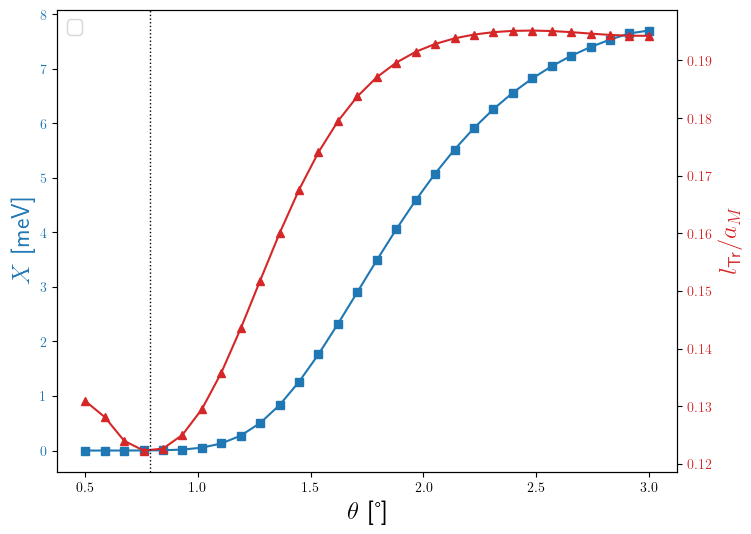

In [12]:
tt = np.linspace(0.0, 1.5, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))

fig, ax = plt.subplots(figsize=(8, 6))

color1 = "tab:blue"
d2X = np.gradient(E, thetas)
ax.plot(thetas, d2X, marker="s", label=r"$X$", color=color1)
ax.set_ylabel(r"$X$ [meV]", fontsize=18, color=color1)
ax.tick_params(axis="y", labelcolor=color1)
#ax.set_ylim([-0.2, 2.2])

ax2 = ax.twinx()
color2 = "tab:red"
d2lg = np.gradient(lg, thetas)
ax2.plot(thetas, d2lg, marker="^", color=color2)
ax2.set_ylabel(r"$l_\text{Tr} / a_M$", fontsize=18, color=color2)
ax2.tick_params(axis="y", labelcolor=color2)
#ax2.set_ylim([0.0, 0.55])
ax2.legend(fontsize=14, loc="upper left")

d2lg = np.gradient(np.gradient(lg, thetas), thetas)
sign_change = np.where(np.diff(np.sign(d2lg)) != 0)[0]

# linearly interpolate the exact theta of each zero crossing
theta_zeros = []
for i in sign_change:
    x0, x1 = thetas[i], thetas[i + 1]
    y0, y1 = d2lg[i], d2lg[i + 1]
    theta_zeros.append(x0 - y0 * (x1 - x0) / (y1 - y0))
    
ax2.axvline(theta_zeros[0], color="black", linestyle=":", linewidth=1)

ax.set_xlabel(r"$\theta$ [°]", fontsize=18)
#ax.set_xlim([0.0, 3.2])
plt.savefig("plots/exchange_metric.pdf", dpi=300, bbox_inches="tight")

In [142]:
thetas = np.linspace(0.2, 1.4, 80)
E = []
t1 = []
lg = []

scale = 4.0

Nx = 50
Ny = 50
resk = 15
sys.psi_deg = 26.0
sys.V = 6.6
D_gate = 1e6

Vlist = [4, 6, 8]

sys.n_shells = 8

E_mat = []
lg_mat = []

for V in tqdm(Vlist):
    sys.V = V

    E = []
    lg = []

    for th in thetas:
        sys.theta_deg = th
        k_points = sys.mesh_k_unit_cell(Nx=24, Ny=24)

        x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
        y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
        X, Y = np.meshgrid(x, y)
        extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
        
        E.append(sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=5))

        integral = sys.integrate_trace(Nx=resk, Ny=resk)
        l_trace = np.sqrt(integral) / sys.aM
        lg.append(l_trace)
    E_mat.append(E)
    lg_mat.append(lg)

100%|██████████| 3/3 [11:12<00:00, 224.26s/it]


0.09422568498638037
0.09248845003471666
0.09274960943759011


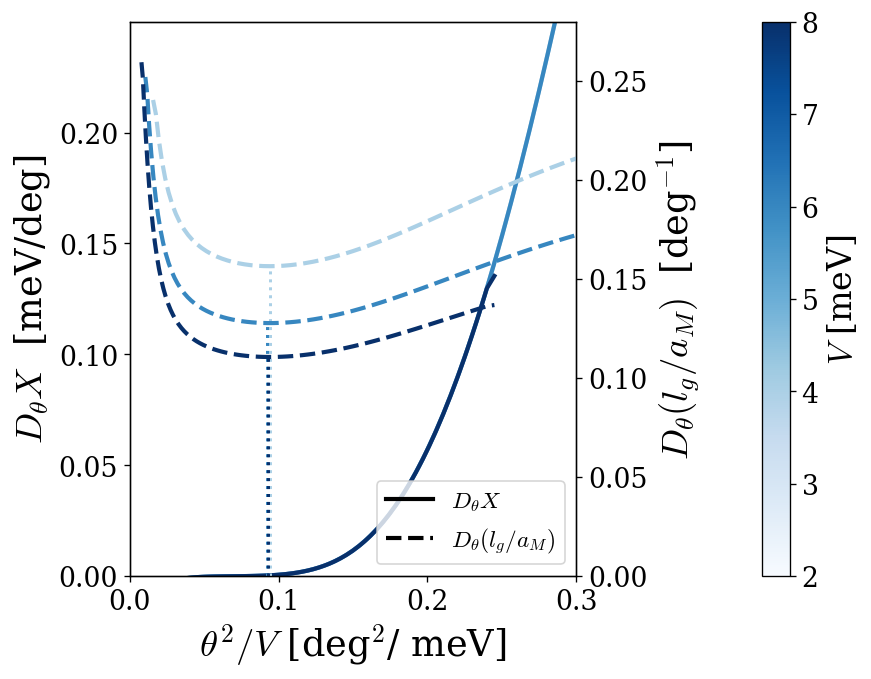

In [176]:
from matplotlib import cm
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(8, 6))
ax2 = ax.twinx()

# Map V values to a grey/black colormap
Vlist = np.array(Vlist)
norm = Normalize(vmin=Vlist.min()/2, vmax=Vlist.max())
cmap = cm.Blues          # reversed grey: low V = light grey, high V = black
cmap_blues = cm.winter_r    # reversed grey: low V = light grey, high V = black
cmap_reds = cm.winter_r     # reversed grey: low V = light grey, high V = black

for i in range(len(Vlist)):
    dX = np.gradient(E_mat[i], thetas)
    dlg = np.gradient(lg_mat[i], thetas)
    imin = np.argmin(dlg)

    d2lg = np.gradient(dlg, thetas)
    sign_change = np.where(np.diff(np.sign(d2lg)) != 0)[0]
    # ax.plot(thetas, E_mat[i], marker='o', color=cmap(norm(Vlist[i])), linewidth=2)
    # ax2.plot(thetas, lg_mat[i], marker='s', color=cmap(norm(Vlist[i])), linewidth=2)
    # ax2.vlines([thetas[sign_change[0]]], ymin=[0], ymax=[dlg[sign_change[0]]], color=cmap(norm(Vlist[i])), linestyle=":", linewidth=0.7)
    # ax.plot(thetas, dX, color=cmap(norm(Vlist[i])), linewidth=2)
    # ax2.plot(thetas, dlg, marker='', color=cmap(norm(Vlist[i])), linewidth=2, linestyle="--")
    # ax.set_xlabel(r"$\theta$ [°]", fontsize=18)
    print(thetas[imin]**2 / Vlist[i])
    ax2.vlines([thetas[imin]**2] / Vlist[i], ymin=[0], ymax=[dlg[sign_change[0]]], color=cmap(norm(Vlist[i])), linestyle=":", linewidth=1.8)
    ax.plot(thetas**2 / Vlist[i], dX, color=cmap(norm(Vlist[i])), linewidth=2.5)
    ax2.plot(thetas**2 / Vlist[i], dlg, marker='', color=cmap(norm(Vlist[i])), linewidth=2.5, linestyle="--")
    ax.set_xlabel(r"$\theta^2 / V$ [deg$^2$/ meV]", fontsize=22)

# Build the colorbar from a ScalarMappable
# sm = cm.ScalarMappable(cmap=cmap, norm=norm)
# sm.set_array([])  # needed for older matplotlib versions
# cbar = fig.colorbar(sm, ax=ax)
# cbar.set_label(r"$V$ [meV]")

ax.set_ylabel(r"$D_\theta X$  [meV/deg]", fontsize=22)
ax2.set_ylabel(r"$D_\theta  (l_g / a_M)$  [deg$^{-1}$]", fontsize=22)
#ax2.set_ylim([0.0, 0.3])
# ax.set_ylabel(r"$J$ [meV]", fontsize=18)
# ax.legend(fontsize=16)
# #ax.set_xlim([0.75, 2.0])
# ax.set_ylim([-.1, .1])

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # needed for older matplotlib versions
cbar = fig.colorbar(sm, ax=ax2, pad=0.25)
cbar.set_label(r"$V$ [meV]", fontsize=20)

from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], color="black", linestyle="-",  linewidth=2.5,
           label=r"$D_\theta X$"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2.5,
           label=r"$D_\theta (l_g/a_M)$"),
]

ax.legend(handles=legend_handles, fontsize=14, loc="lower right")
ax.set_xlim([0.0, 0.3])
ax.set_xticks([0.0, 0.1, 0.2, 0.3])
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.set_ylim([0.0, .25])
ax2.set_ylim([0.0, .28])
plt.savefig("plots/derivative_metric.svg", dpi=300, bbox_inches="tight")

### Hopping integral

In [89]:
thetas = np.linspace(0.5, 3.0, 20)
t1 = []
t2 = []
t3 = []

scale = 5.0

Nx = 80
Ny = 80

for th in tqdm(thetas):
    sys.theta_deg = th
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    t1.append(sys.hopping_integral(X, Y, k_points, order=1))
    t2.append(sys.hopping_integral(X, Y, k_points, order=2))
    t3.append(sys.hopping_integral(X, Y, k_points, order=3))

  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [02:50<00:00,  8.54s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


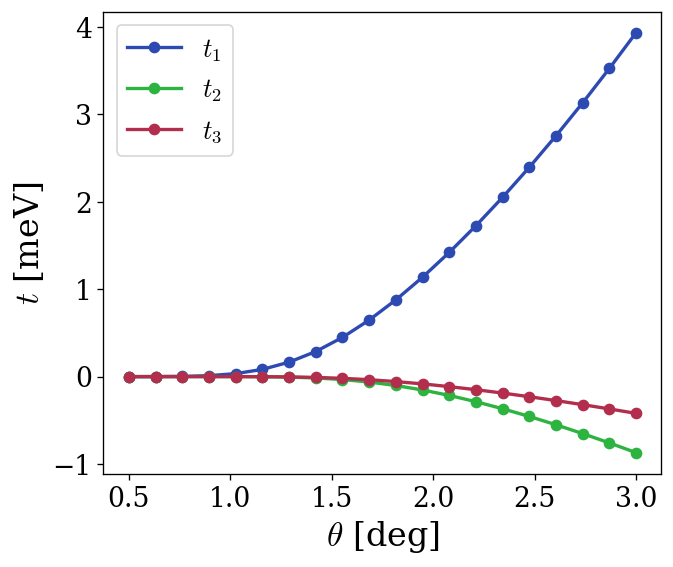

In [90]:
fig, ax = plt.subplots()

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, t1, marker="o", label=r"$t_1$", color=cols[0])
ax.plot(thetas, t2, marker="o", label=r"$t_2$", color=cols[1])
ax.plot(thetas, t3, marker="o", label=r"$t_3$", color=cols[2])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)
plt.savefig("plots/nearest_hopping.pdf", dpi=300, bbox_inches="tight")

In [95]:
thetas

array([0.5       , 0.63157895, 0.76315789, 0.89473684, 1.02631579,
       1.15789474, 1.28947368, 1.42105263, 1.55263158, 1.68421053,
       1.81578947, 1.94736842, 2.07894737, 2.21052632, 2.34210526,
       2.47368421, 2.60526316, 2.73684211, 2.86842105, 3.        ])

In [91]:
sys.theta_deg = 2.0
psis = np.linspace(0, 120, 21)
t1 = []
t1_kspace = []
t2 = []
t2_kspace = []
t3 = []
t3_kspace = []

for p in tqdm(psis):
    sys.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##
    
    if p > 60:
        Rshift = RB
    else:
        Rshift = np.zeros(2)
        
    t1.append(sys.hopping_integral(X, Y, k_points, order=1, trial_center=Rshift))
    t1_kspace.append(sys.hopping_integral_kspace(k_points, order=1, band_index=0))
    t2.append(sys.hopping_integral(X, Y, k_points, order=2, trial_center=Rshift))
    t2_kspace.append(sys.hopping_integral_kspace(k_points, order=2, band_index=0))
    t3.append(sys.hopping_integral(X, Y, k_points, order=3, trial_center=Rshift))
    t3_kspace.append(sys.hopping_integral_kspace(k_points, order=3, band_index=0))

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [03:13<00:00,  9.19s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


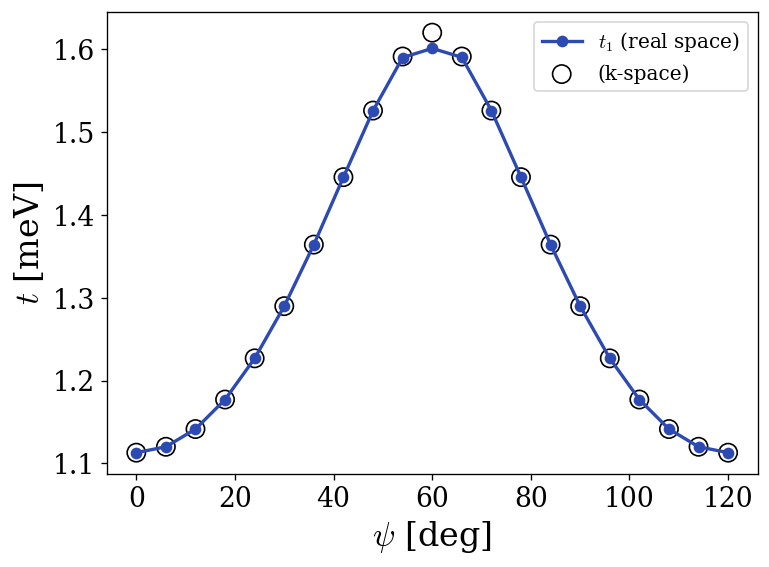

In [93]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, t1, marker="o", label=r"$t_1$ (real space)", color=cols[0])
# ax.plot(psis, t2, marker="o", label=r"$t_2$ (real space)", color=cols[1])
# ax.plot(psis, t3, marker="o", label=r"$t_3$ (real space)", color=cols[2])
ax.scatter(psis, t1_kspace, marker="o", label=r"(k-space)", color="k", s=120, facecolor="none", linewidth=1)
# ax.scatter(psis, t2_kspace, marker="o", label=None, color="k", s=150, facecolor="none", linewidth=1)
# ax.scatter(psis, t3_kspace, marker="o", label=None, color="k", s=150, facecolor="none", linewidth=1)
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=12)
plt.savefig("plots/nearest_hopping.pdf", dpi=300, bbox_inches="tight")

/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


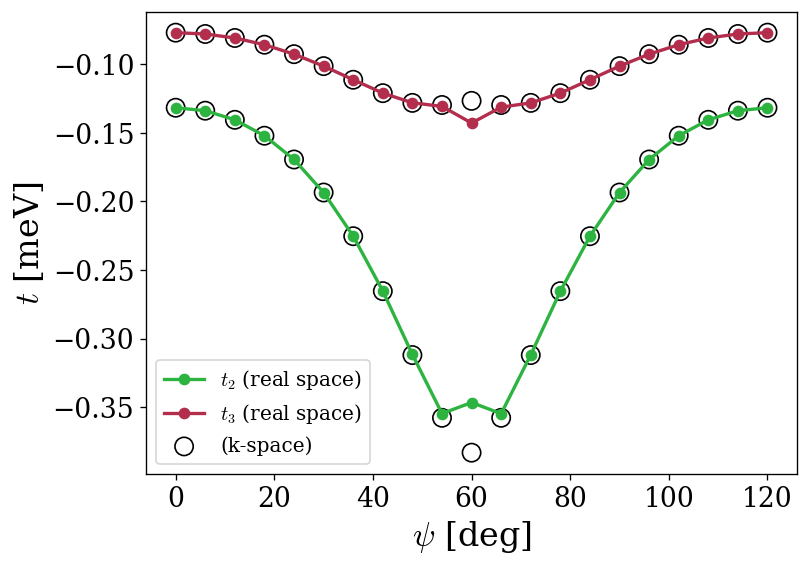

In [94]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

# ax.plot(psis, t1, marker="o", label=r"$t_1$ (real space)", color=cols[0])
ax.plot(psis, t2, marker="o", label=r"$t_2$ (real space)", color=cols[1])
ax.plot(psis, t3, marker="o", label=r"$t_3$ (real space)", color=cols[2])
# ax.scatter(psis, t1_kspace, marker="o", label=r"(k-space)", color="k", s=120, facecolor="none", linewidth=1)
ax.scatter(psis, t2_kspace, marker="o", label=r"(k-space)", color="k", s=120, facecolor="none", linewidth=1)
ax.scatter(psis, t3_kspace, marker="o", label=None, color="k", s=120, facecolor="none", linewidth=1)
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=12)
plt.savefig("plots/nearest_hopping.pdf", dpi=300, bbox_inches="tight")

### Effective spin coupling

In [ ]:
thetas = np.linspace(0.6, 3.0, 20)
exchange = []
t1 = []
U0 = []

scale = 4.0

Nx = 80
Ny = 80
resk = 15
sys.psi_deg = 10.0
Vlist = [4, 5, 6, 7, 8]
D_gate = 1e6
epsilon = 10.0
sys.n_shells = 8

J_mat = []

for V in tqdm(Vlist):
    sys.V = V
    j_temp = []
    exchange = []
    t1 = []
    U0 = []
    for th in thetas:
        sys.theta_deg = th
        k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

        x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
        y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
        X, Y = np.meshgrid(x, y)
        extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
        
        exchange.append(sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=epsilon))
        t1.append(sys.hopping_integral(X, Y, k_points, order=1))
        U0.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate, epsilon=epsilon))

    j_temp = (4 * (np.array(t1))**2) / (np.array(U0)) - 2 * np.array(exchange)
    J_mat.append(j_temp)

100%|██████████| 5/5 [07:59<00:00, 95.90s/it] 


/Users/higuera/Desktop/UniStuttgart/flatiron/project/flatiron/diagonalization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/flatiron/diagonalization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


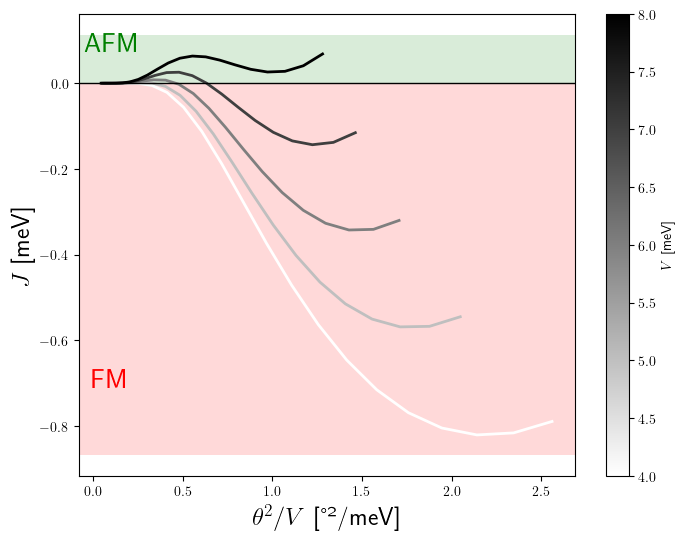

In [61]:
from matplotlib import cm
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(8, 6))

# Map V values to a grey/black colormap
Vlist = np.array(Vlist)
norm = Normalize(vmin=Vlist.min(), vmax=Vlist.max())
cmap = cm.gray_r   # reversed grey: low V = light grey, high V = black

for i in range(len(Vlist)):
    ax.plot((thetas**2) / Vlist[i], J_mat[i], color=cmap(norm(Vlist[i])), linewidth=2)

# Build the colorbar from a ScalarMappable
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # needed for older matplotlib versions
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"$V$ [meV]")

ax.set_xlabel(r"$\theta^2 / V$ [°²/meV]", fontsize=18)
ax.set_ylabel(r"$J$ [meV]", fontsize=18)
#ax.set_xlim([0.0, 0.8])
#ax.set_ylim([-.3, .3])

ymin, ymax = ax.get_ylim()
ax.axhline(y=0, color="black", linestyle="-", linewidth=1)
ax.axhspan(0, ax.get_ylim()[1], facecolor="green", alpha=0.15)   # positive
ax.text(0.1, ymax * 0.8, "AFM",
        color="green", fontsize=20, ha="center", va="center")
ax.axhspan(ax.get_ylim()[0], 0, facecolor="red", alpha=0.15)     # negative
ax.text(0.1, ymin * 0.8, "FM",
        color="red", fontsize=20, ha="center", va="center")

plt.savefig("plots/spin_coupling.pdf", dpi=300, bbox_inches="tight")

In [ ]:
thetas = np.linspace(0.6, 5.0, 20)
exchange = []
t1 = []
U0 = []

scale = 4.0

Nx = 60
Ny = 60
resk = 15
sys.psi_deg = 26.0
Vlist = np.linspace(4, 14, 20)
D_gate = 1e6
epsilon = 10

sys.n_shells = 8
J_mat = []

for V in Vlist:
    sys.V = V
    j_temp = []
    exchange = []
    t1 = []
    U0 = []
    ref_energies = []
    for th in thetas:
        sys.theta_deg = th
        k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

        x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
        y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
        X, Y = np.meshgrid(x, y)
        extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
        
        exchange.append(sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=epsilon))
        t1.append(sys.hopping_integral(X, Y, k_points, order=1))
        U0.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate, epsilon=epsilon))
        ref_energies.append( utils.HBAR2_M * np.linalg.norm(sys.kappa)**2 )

    j_temp = (4 * (np.array(t1))**2) / (np.array(U0)) - 2 * np.array(exchange)
    J_mat.append(j_temp / np.array(ref_energies))

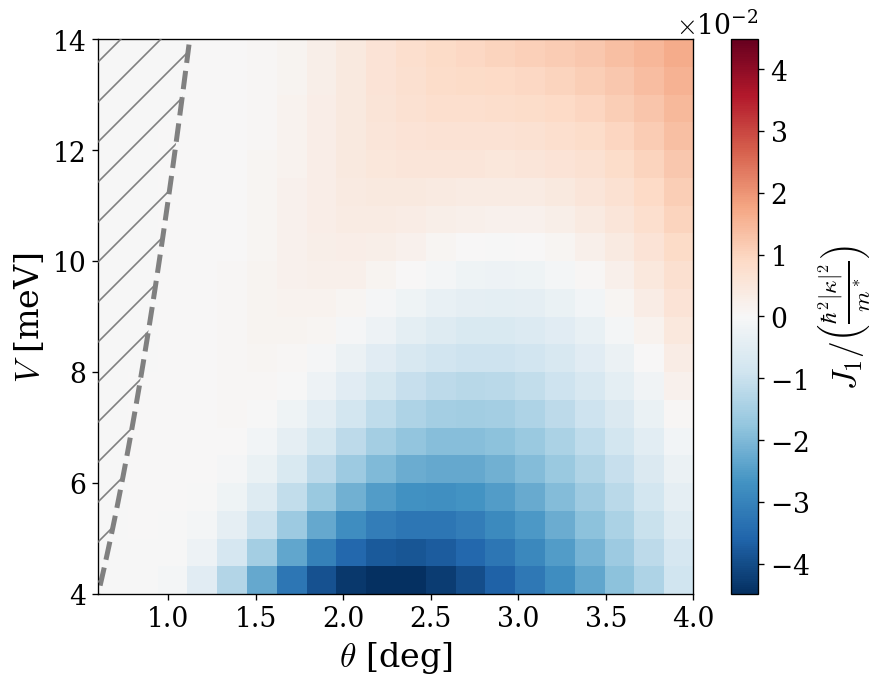

In [ ]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import ScalarFormatter

data = np.real(J_mat)

v_lim = np.max([np.abs(data.min()), np.abs(data.max())])
norm = TwoSlopeNorm(
    vmin=-v_lim,
    vcenter=0,
    vmax=v_lim
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    data,
    extent=[thetas[0], thetas[-1], Vlist[0], Vlist[-1]],
    origin='lower',
    cmap='RdBu_r',
    norm=norm,
    aspect='auto',
    interpolation='none'
)

tt = np.linspace(0.0, 1.5, 100)
plt.plot(tt, (tt**2) / .09, '--', color='gray', linewidth=3)

vv = np.linspace(Vlist[0], Vlist[-1], 200)
x_curve = np.sqrt(0.09 * vv)          # invert V = θ²/0.09  ->  θ = sqrt(0.09 V)

ax.fill_betweenx(
    vv, thetas[0], x_curve,
    facecolor='none',      # no fill, just stripes
    hatch='/',
    edgecolor='gray',
    linewidth=0.0,
    zorder=3,              # keep hatching above the imshow
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$J_1/\left(\frac{\hbar^2 |\kappa|^2}{m^*}\right)$", fontsize=20)
formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((0, 0))   # Always use scientific notation
cbar.formatter = formatter
cbar.update_ticks()

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$V$ [meV]", fontsize=20)
ax.set_ylim([Vlist[0], Vlist[-1]])
ax.set_xlim([thetas[0], thetas[-1]])
plt.savefig("plots/phase_diagram_psi"+str(sys.psi_deg)+"_epsilon"+str(epsilon)+"_D"+str(D_gate)+"xxx.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [73]:
thetas = np.linspace(1.5, 3.0, 20)
exchange = []
t1 = []
U0 = []

scale = 4.0

Nx = 60
Ny = 60
resk = 15
sys.psi_deg = 26.0
V_fix = 11
sys.V = V_fix
inv_epsilon = np.linspace(0.04, 0.15, 20)
D_gate = 1e6

sys.n_shells = 8
J_mat = []

for inv_eps in tqdm(inv_epsilon):
    j_temp = []
    exchange = []
    t1 = []
    U0 = []
    for th in thetas:
        sys.theta_deg = th
        k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

        x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
        y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
        X, Y = np.meshgrid(x, y)
        extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
        
        exchange.append(sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=1 / inv_eps))
        t1.append(sys.hopping_integral(X, Y, k_points, order=1))
        U0.append(sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate, epsilon=1 / inv_eps))

    j_temp = (4 * (np.array(t1))**2) / (np.array(U0)) - 2 * np.array(exchange)
    J_mat.append(j_temp)

  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [27:49<00:00, 83.50s/it]


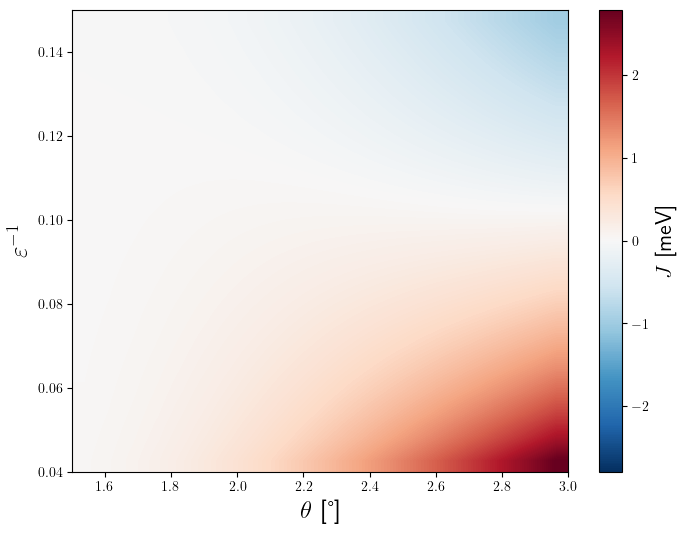

In [81]:
from matplotlib.colors import TwoSlopeNorm

data = np.real(J_mat)

v_lim = np.max([np.abs(data.min()), np.abs(data.max())])
norm = TwoSlopeNorm(
    vmin=-v_lim,
    vcenter=0,
    vmax=v_lim
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    data,
    extent=[thetas[0], thetas[-1], inv_epsilon[0], inv_epsilon[-1]],
    origin='lower',
    cmap='RdBu_r',
    norm=norm,
    aspect='auto',
    interpolation='bilinear'
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$J$ [meV]", fontsize=16)

ax.set_xlabel(r"$\theta$ [°]", fontsize=18)
ax.set_ylabel(r"$\varepsilon^{-1}$", fontsize=18)
plt.savefig("plots/phase_diagram_psi"+str(sys.psi_deg)+"_V"+str(sys.V)+"_D"+str(D_gate)+".pdf", dpi=300, bbox_inches="tight")
plt.show()